Dataset loaded successfully!
Dataset shape: (1599, 12)

First five rows:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  q

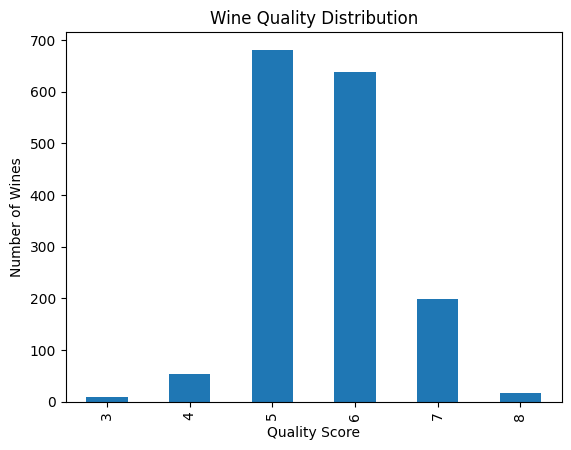


Model Accuracy:
80.62 %

Classification Report:
                precision    recall  f1-score   support

 Lower quality       0.78      0.82      0.80       149
Higher quality       0.83      0.80      0.81       171

      accuracy                           0.81       320
     macro avg       0.81      0.81      0.81       320
  weighted avg       0.81      0.81      0.81       320



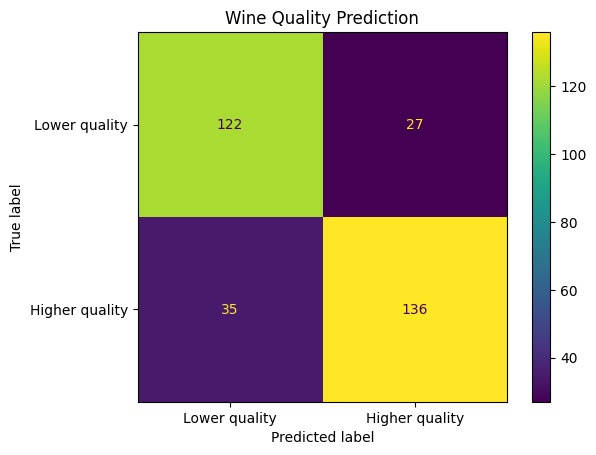

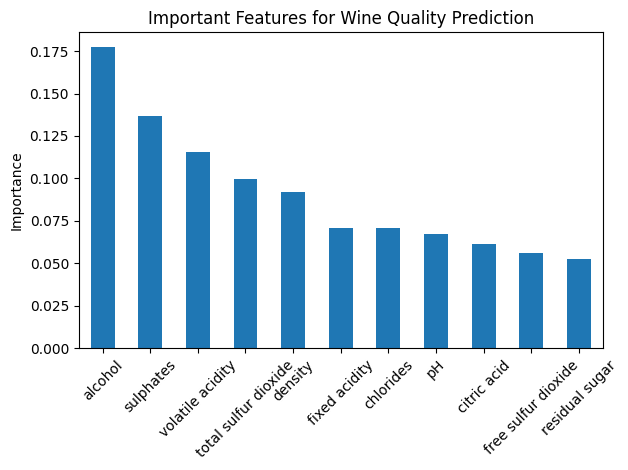


Task completed successfully!


In [ ]:
# TASK: WINE QUALITY PREDICTION

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Load dataset directly
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/wine-quality/"
    "winequality-red.csv"
)

df = pd.read_csv(url, sep=';')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

# Check dataset information
print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

# Visualize wine quality
df['quality'].value_counts().sort_index().plot(kind='bar')
plt.title('Wine Quality Distribution')
plt.xlabel('Quality Score')
plt.ylabel('Number of Wines')
plt.show()

# Prepare target variable
# Quality 6 or above = higher quality
df['quality_label'] = (df['quality'] >= 6).astype(int)

X = df.drop(columns=['quality', 'quality_label'])
y = df['quality_label']

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

# Predict
predictions = model.predict(X_test)

# Evaluate
print("\nModel Accuracy:")
print(round(accuracy_score(y_test, predictions) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    target_names=['Lower quality', 'Higher quality']
))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=['Lower quality', 'Higher quality']
)

plt.title('Wine Quality Prediction')
plt.show()

# Feature importance
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

importance.plot(kind='bar')
plt.title('Important Features for Wine Quality Prediction')
plt.ylabel('Importance')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("\nTask completed successfully!")